In [1]:
import warnings
warnings.simplefilter('ignore', category=FutureWarning)
import scanpy as sc
import logging
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s'
)
import glob
os.chdir('../')
from src.workflow_utils import read_data_sheet

In [2]:
%load_ext autoreload
%autoreload 2

In [6]:
# Input data dirs
dirs = [
    '/home/user/proj_home/dl/perturb-seq/data/raw'
]

In [25]:
# Collect all .h5ad files
files = []
for d in dirs:
    _files = glob.glob(f'{d}/**/*.h5ad', recursive=True)
    files.extend(_files)
files = pd.Series(files)
# Filter list of files for dataset sheet names
dataset_sheet = pd.read_csv('resources/datasets/meta/training.csv', index_col=0)
# Get dataset names
ds_names = dataset_sheet.index
ds_mask = files.apply(lambda x: os.path.basename(x)).str.split('.h5ad').str[0].isin(ds_names)
files = files[ds_mask].values
logging.info(f'# Dataset files: {files.shape[0]}')

2026-03-19 14:26:35,648 - INFO - # Dataset files: 19


In [26]:
from src.info import collect_meta_from_files

obs, vars_dict = collect_meta_from_files(files)

2026-03-19 14:26:36,686 - INFO - Reading meta data of /home/user/proj_home/dl/perturb-seq/data/raw/Marson2025_D3_Rest.h5ad
2026-03-19 14:26:41,445 - INFO - "perturbation" not found in adata.obs, looking for alternatives.
2026-03-19 14:26:41,449 - INFO - Found "perturbed_gene_name" as perturbation column
2026-03-19 14:26:41,452 - INFO - control not found in "perturbation", looking for alternatives.
2026-03-19 14:26:41,511 - INFO - Found "NTC" as control key
2026-03-19 14:26:41,546 - INFO - Filtering column "perturbation" for single perturbations only
2026-03-19 14:26:49,302 - INFO - Dataset .var indices are ensembl ids, attempting transfer to gene symbols using internal adata.var.
2026-03-19 14:26:50,032 - INFO - Reading meta data of /home/user/proj_home/dl/perturb-seq/data/raw/Marson2025_D1_Stim48hr.h5ad
2026-03-19 14:26:54,623 - INFO - "perturbation" not found in adata.obs, looking for alternatives.
2026-03-19 14:26:54,626 - INFO - Found "perturbed_gene_name" as perturbation column
20

2026-03-19 14:28:40,796 - INFO - Filtering column "perturbation" for single perturbations only
2026-03-19 14:28:48,481 - INFO - Dataset .var indices are ensembl ids, attempting transfer to gene symbols using internal adata.var.
2026-03-19 14:28:49,232 - INFO - Reading meta data of /home/user/proj_home/dl/perturb-seq/data/raw/ReplogleWeissman2022_rpe1.h5ad
2026-03-19 14:28:49,839 - INFO - Filtering column "perturbation" for single perturbations only
2026-03-19 14:28:50,099 - INFO - Reading meta data of /home/user/proj_home/dl/perturb-seq/data/raw/XAtlas2025_HEK293T.h5ad
2026-03-19 14:28:56,725 - INFO - "perturbation" not found in adata.obs, looking for alternatives.
2026-03-19 14:28:56,728 - INFO - Found "gene_target" as perturbation column
2026-03-19 14:28:56,732 - INFO - control not found in "perturbation", looking for alternatives.
2026-03-19 14:28:56,829 - INFO - Found "Non-Targeting" as control key
2026-03-19 14:28:56,887 - INFO - Filtering column "perturbation" for single perturba

In [27]:
# Group dataset conditions
dataset_sheet['ds_label'] = dataset_sheet['publication index'] + '_' + dataset_sheet['dataset index'].str.split('_').str[-1]
# Add dataset information
obs = obs.merge(dataset_sheet, left_on='dataset', right_index=True)

In [30]:
# Set dataset filtering key
ctx_key = 'dataset'
# Filter .obs for valid dataset and perturbation combinations
min_cells_per_perturbation = 50
counts = obs.groupby([ctx_key, "perturbation"]).transform("size")
obs_mask = counts >= min_cells_per_perturbation
obs = obs[obs_mask].copy()

<Figure size 1920x1440 with 0 Axes>

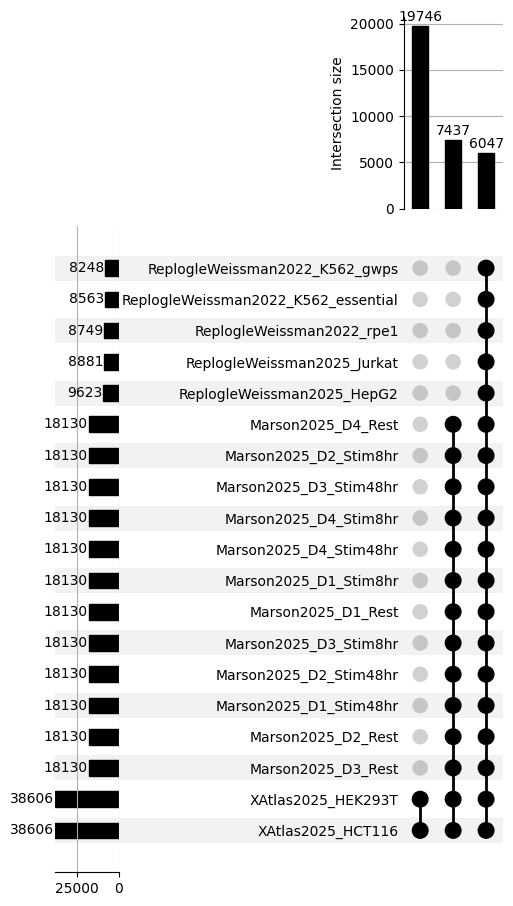

In [31]:
from upsetplot import UpSet, from_contents
import matplotlib.pyplot as plt

# Define input sets
sets = {ds: set(v.index) for ds, v in vars_dict.items()}
data = from_contents(sets)
# Plot
plt.figure(dpi=300)
us = UpSet(data, subset_size="count", sort_by="cardinality", min_subset_size=1000, show_counts=True)
us.plot()
plt.show()

In [32]:
# Calculate feature overlap
feature_pool = set.intersection(*[set(v.index) for v in vars_dict.values()])
logging.info(f'Found {len(feature_pool)} shared features across all datasets.')

2026-03-19 14:40:12,748 - INFO - Found 6047 shared features across all datasets.


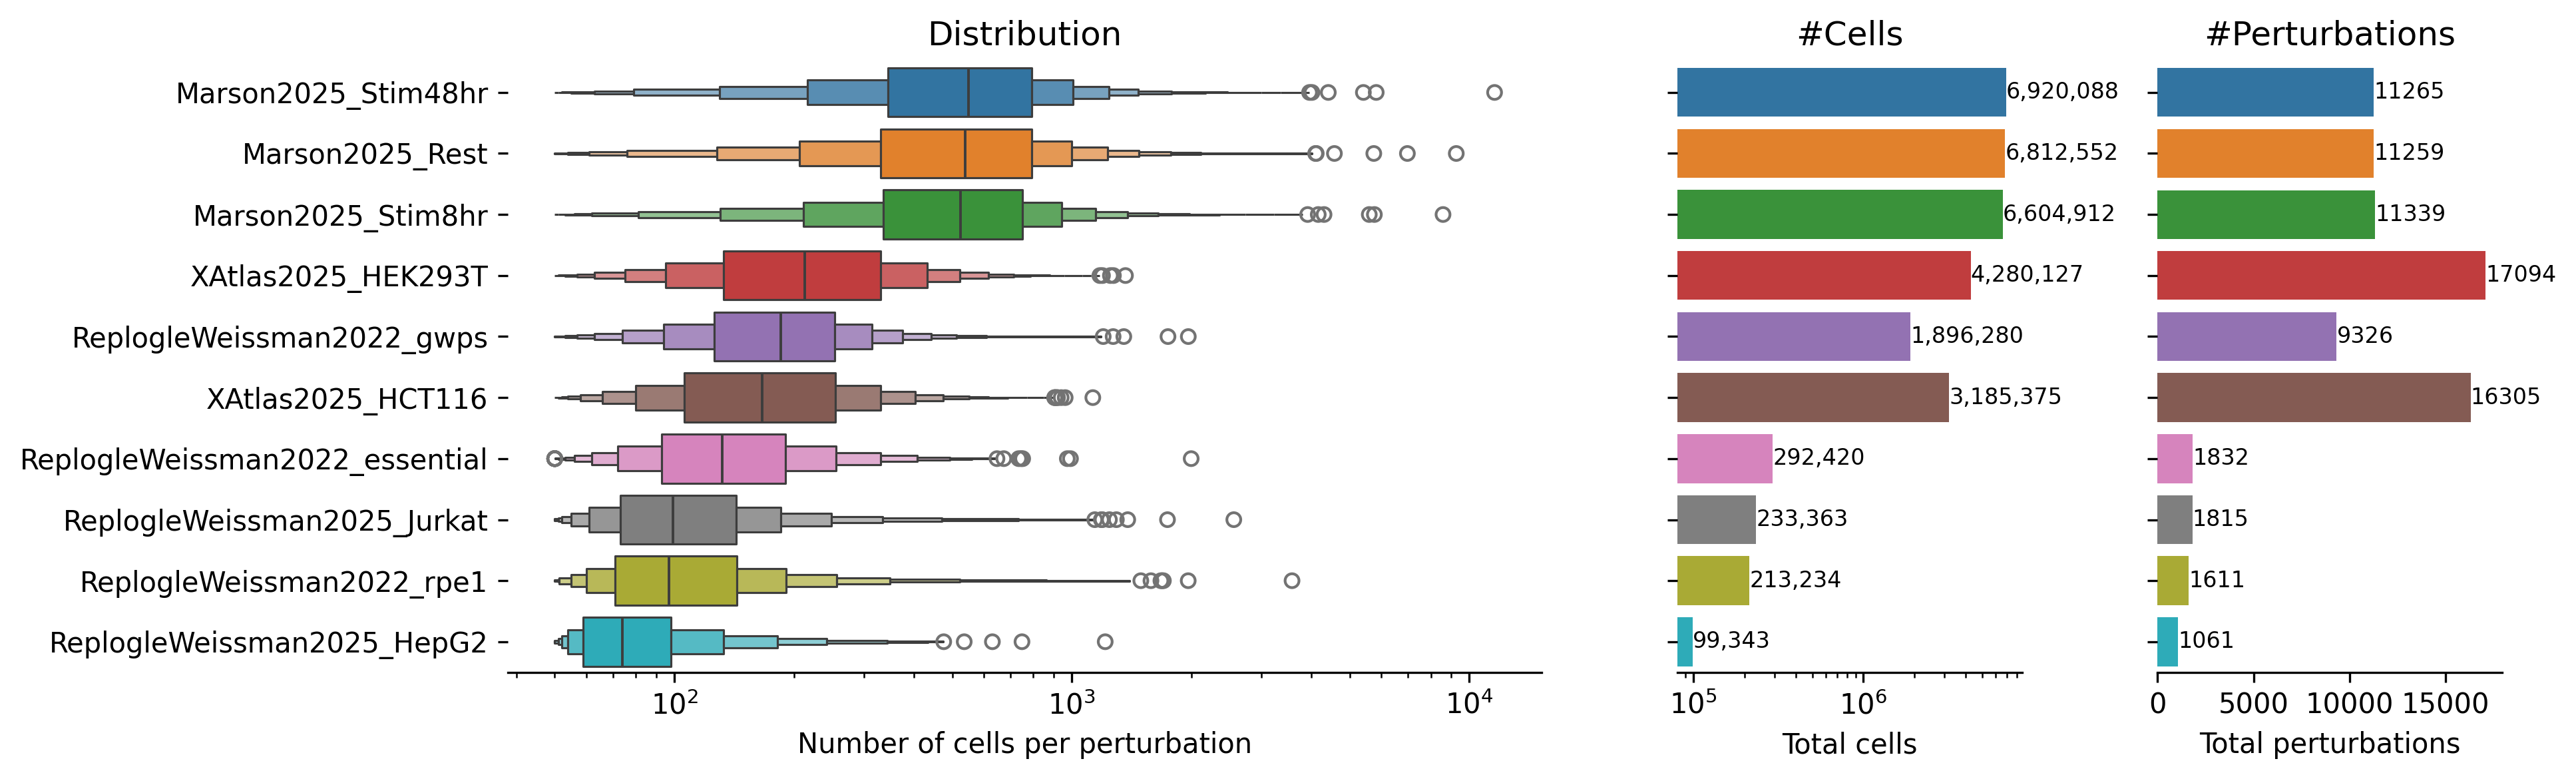

In [33]:
# --- aggregate data ---
meta = obs
by = 'ds_label'
df = meta.groupby([by, 'perturbation']).size().reset_index()
df.columns = [by, 'perturbation', 'n_cells']
# Filter data by minimum amount of cells per dataset
min_cells_mask = df.n_cells > 0
# Filter by minimum amount of perturbations per dataset
cppd = df.groupby(by, observed=True).perturbation.nunique()
min_perts_mask = df[by].isin(cppd[cppd > 50].index.values)
# Remove control cells (extreme outliers)
no_ctrl_mask = df.perturbation != 'control'
mask = (min_cells_mask & min_perts_mask & no_ctrl_mask)
df = df[mask].copy()
# Log cell number
df['n_cells_log'] = np.log(df.n_cells)

# order datasets by median log count
order = df.groupby(by)['n_cells_log'].median().sort_values(ascending=False).index
df[by] = pd.Categorical(df[by], categories=order, ordered=True)

# total cells per dataset
total_counts = df.groupby(by)['n_cells'].sum().reindex(order)

# total perturbations per dataset (context)
total_perturbations = (
    df.groupby(by)['perturbation']
    .nunique()
    .reindex(order)
)

# --- plotting ---
fig, (ax1, ax2, ax3) = plt.subplots(
    1, 3,
    figsize=(13, len(order) * 0.4),
    dpi=300,
    sharey=True,
    gridspec_kw={'width_ratios': [3, 1, 1]}
)

# --- left: boxenplot of per-perturbation log counts ---
sns.boxenplot(
    data=df,
    x='n_cells',
    y=by,
    hue=by,
    palette='tab10',
    dodge=False,
    legend=False,
    ax=ax1
)
ax1.set_xscale('log')
ax1.set_xlabel('Number of cells per perturbation')
ax1.set_ylabel('')
ax1.set_title('Distribution')

# --- right: barplot of total counts per dataset (log scale) ---
colors = sns.color_palette('tab10', n_colors=len(order))
bars = sns.barplot(
    x=total_counts.values,
    y=total_counts.index,
    palette=colors,
    ax=ax2
)

# log scale
ax2.set_xscale('log')
ax2.set_xlabel('Total cells')
ax2.set_title('#Cells')

# add numeric labels to each bar
for bar, value in zip(bars.patches, total_counts.values):
    ax2.text(
        value,
        bar.get_y() + bar.get_height() / 2,
        f'{int(value):,}',  # formatted with thousands separator
        va='center',
        ha='left',
        fontsize=8
    )
    
bars2 = sns.barplot(
    x=total_perturbations.values,
    y=total_perturbations.index,
    palette=colors,
    ax=ax3
)

ax3.set_xlabel('Total perturbations')
ax3.set_title('#Perturbations')

# add numeric labels
for bar, value in zip(bars2.patches, total_perturbations.values):
    ax3.text(
        value,
        bar.get_y() + bar.get_height() / 2,
        f'{int(value)}',
        va='center',
        ha='left',
        fontsize=8
    )

# adjust layout / aesthetics
sns.despine(ax=ax1, left=True)
sns.despine(ax=ax2, left=True)
sns.despine(ax=ax3, left=True)
plt.tight_layout()
plt.show()


In [34]:
from upsetplot import UpSet, from_contents
import matplotlib.pyplot as plt

# Define input sets
by = 'ds_label'
ppd = obs.groupby(by).perturbation.unique()
sets = {i: set(ps) for i, ps in ppd.items() if len(ps) >= 50}
data = from_contents(sets)
# Plot
plt.figure(dpi=300)
us = UpSet(data, subset_size="count", sort_by="cardinality", min_subset_size=100, show_counts=True)
us.plot()
plt.savefig(f'figures/database_overview_{by}_upset.svg', dpi=300)
plt.savefig(f'figures/database_overview_{by}_upset.png', dpi=120)
plt.close()

<Figure size 1920x1440 with 0 Axes>

In [35]:
from src.info import build_perturbation_pool

perturbation_pool = build_perturbation_pool(obs, min_dataset_frac=0.6, dataset_col='ds_label')

2026-03-19 14:40:39,622 - INFO - 
Pool: 7197 perturbations (min 6 datasets)
2026-03-19 14:40:39,623 - INFO - ------------------------------------------------------------
2026-03-19 14:40:39,624 - INFO - Marson2025_Rest                          6650/7197 ( 92.4%)
2026-03-19 14:40:39,625 - INFO - Marson2025_Stim48hr                      6643/7197 ( 92.3%)
2026-03-19 14:40:39,626 - INFO - Marson2025_Stim8hr                       6670/7197 ( 92.7%)
2026-03-19 14:40:39,626 - INFO - ReplogleWeissman2022_essential           1328/7197 ( 18.5%)
2026-03-19 14:40:39,627 - INFO - ReplogleWeissman2022_gwps                7167/7197 ( 99.6%)
2026-03-19 14:40:39,628 - INFO - ReplogleWeissman2022_rpe1                1355/7197 ( 18.8%)
2026-03-19 14:40:39,628 - INFO - ReplogleWeissman2025_HepG2                870/7197 ( 12.1%)
2026-03-19 14:40:39,629 - INFO - ReplogleWeissman2025_Jurkat              1478/7197 ( 20.5%)
2026-03-19 14:40:39,630 - INFO - XAtlas2025_HCT116                        7002/7197 ( 

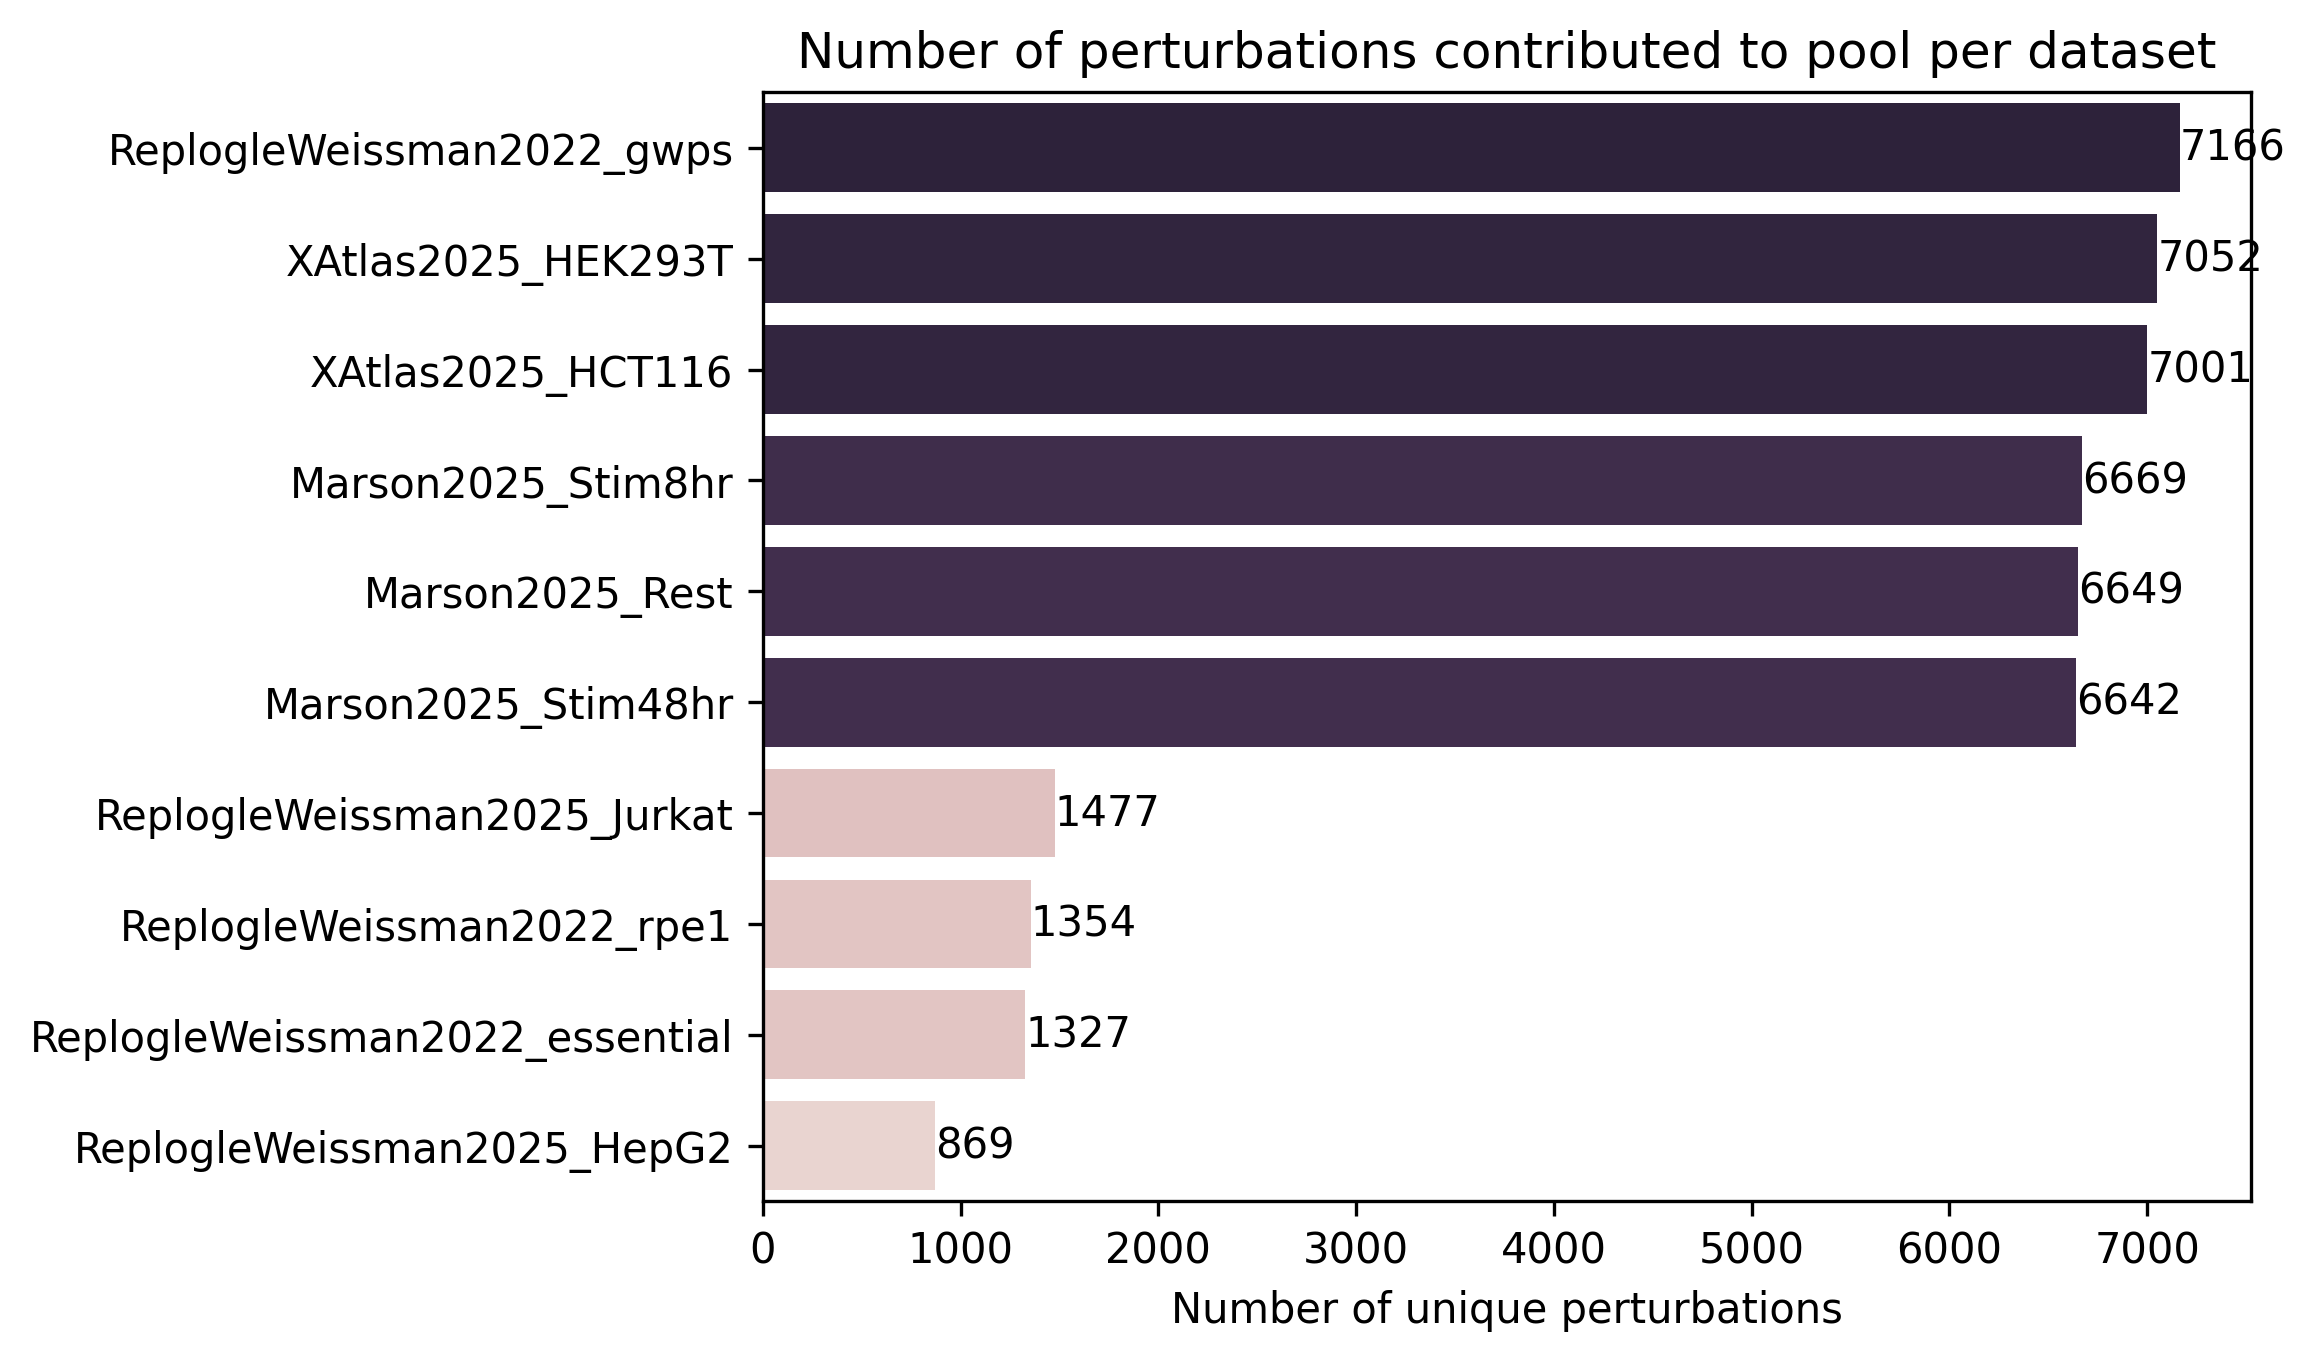

In [36]:
meta = obs
by = 'ds_label'
df = meta[(meta.perturbation.isin(perturbation_pool)) & (meta.perturbation!='control')]
df = df.groupby(by).perturbation.nunique().reset_index().sort_values('perturbation', ascending=False)
fig = plt.figure(dpi=300)
ax = sns.barplot(df, x='perturbation', y=by, orient='y', hue='perturbation', order=df[by].values, legend=False)
for c in ax.containers:
    ax.bar_label(c, fontsize=10)
plt.title('Number of perturbations contributed to pool per dataset')
plt.xlabel('Number of unique perturbations')
plt.ylabel('')
plt.show()

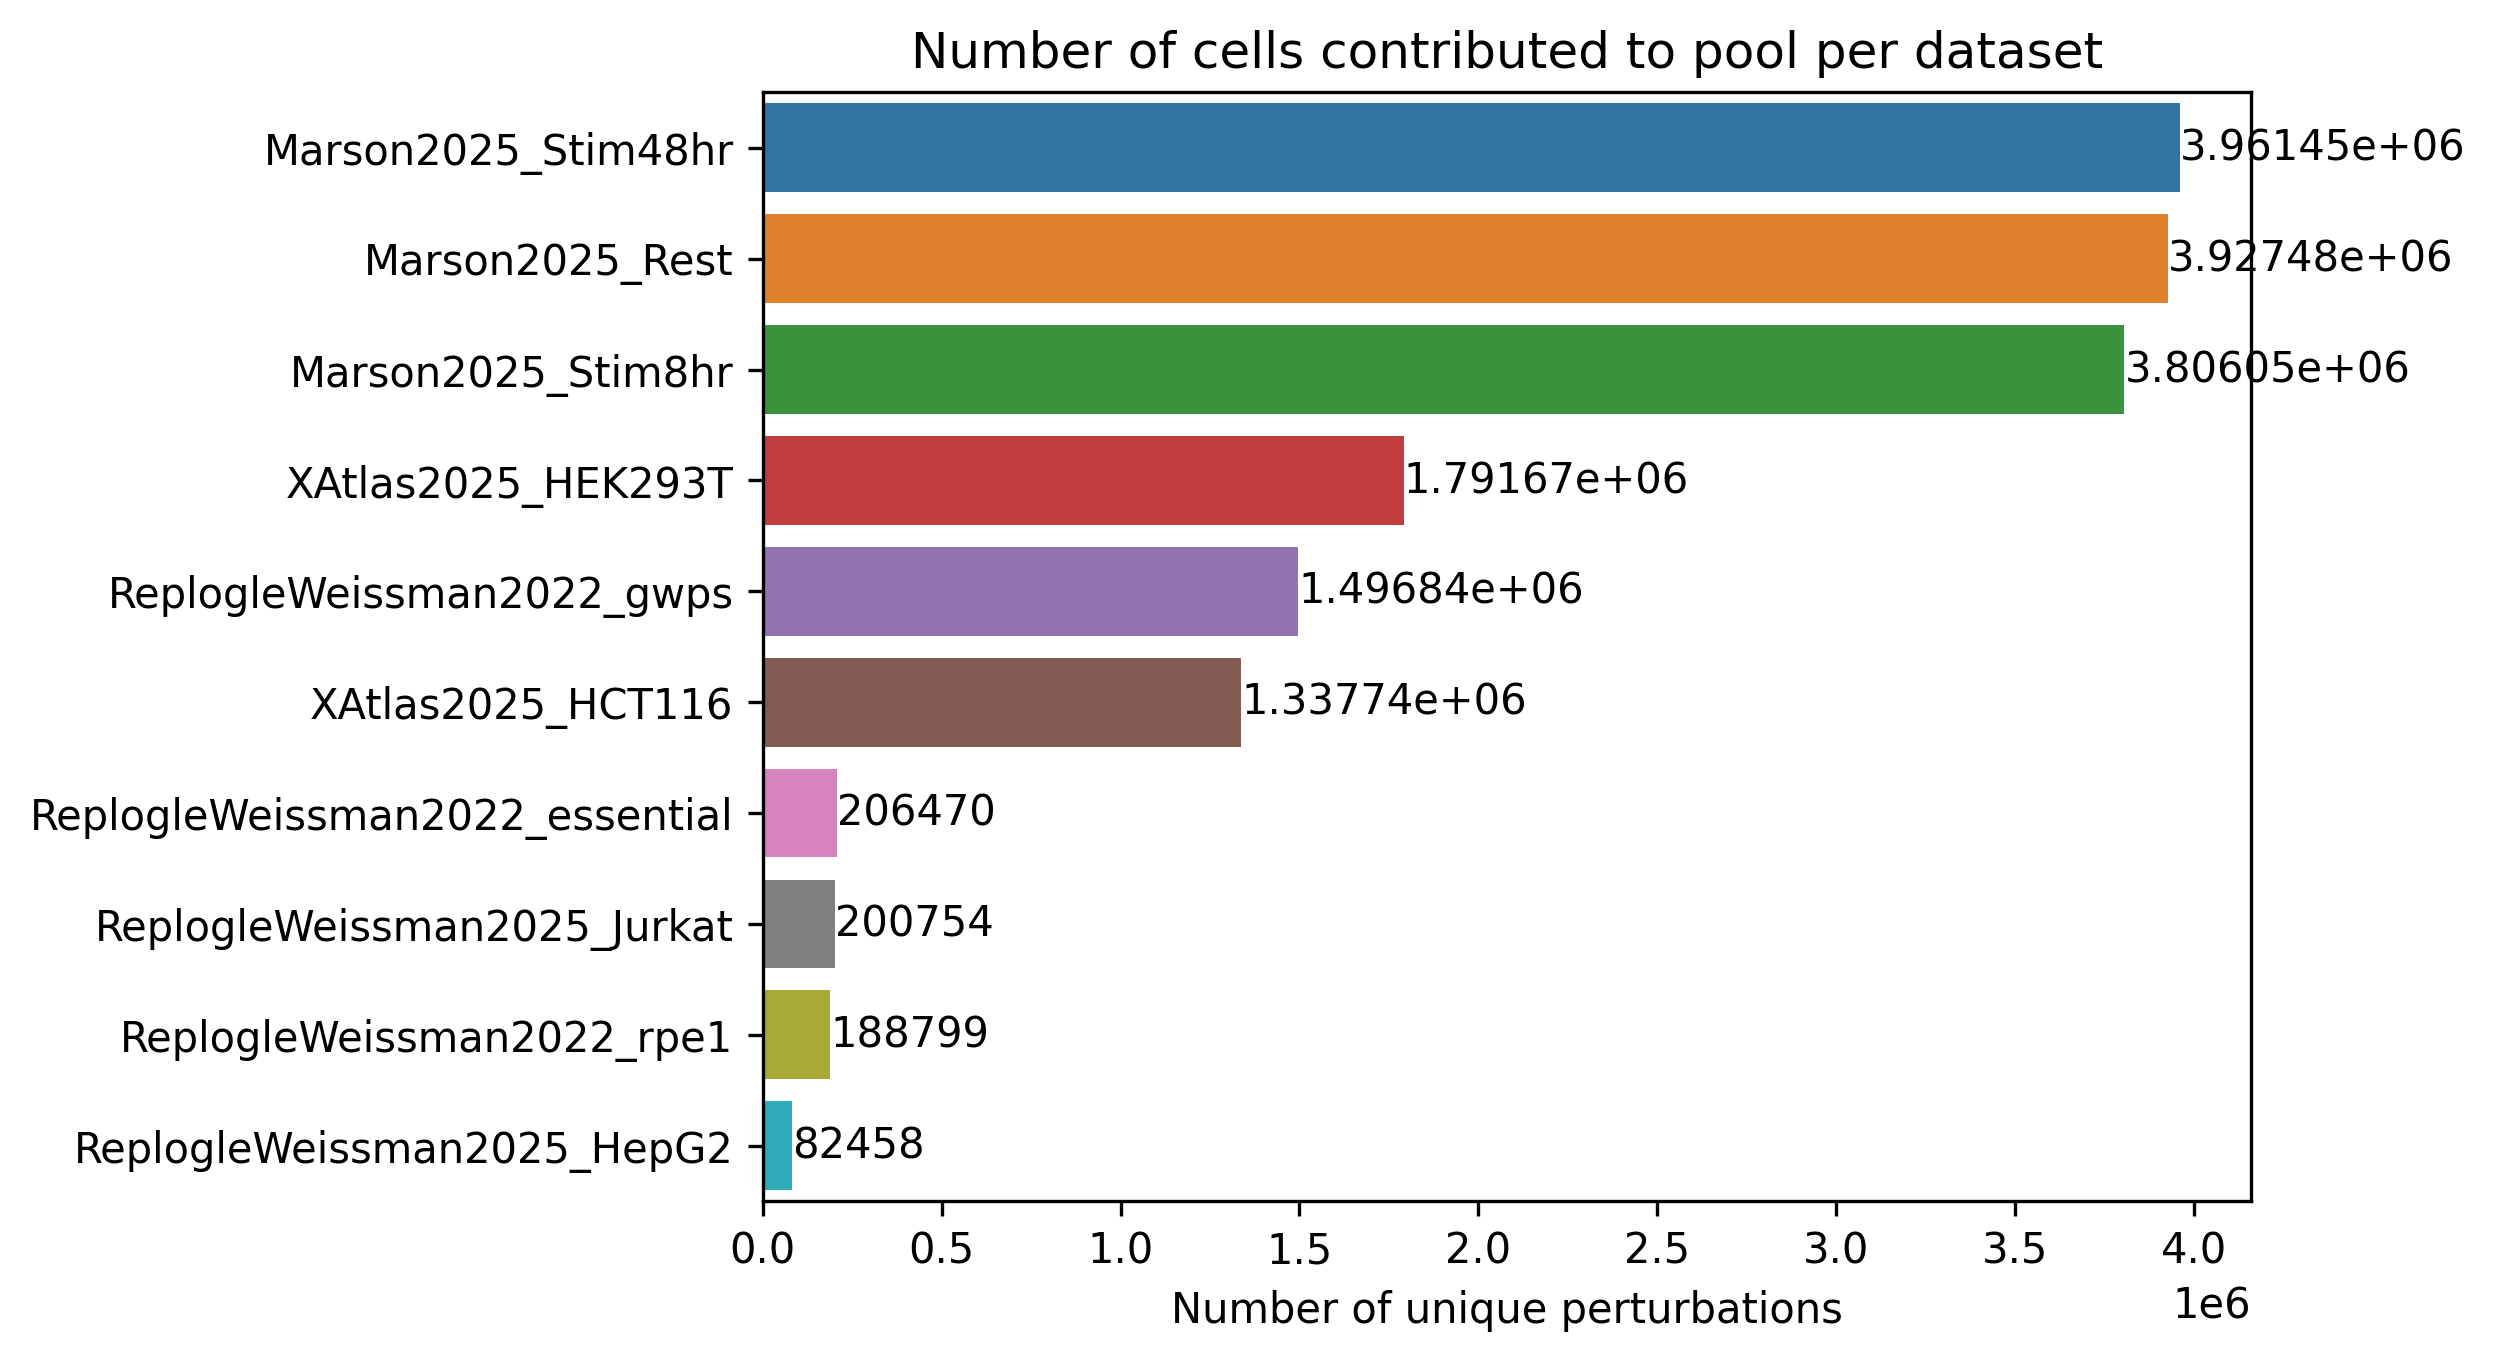

In [37]:
meta = obs
by = 'ds_label'
df = meta[(meta.perturbation.isin(perturbation_pool)) & (meta.perturbation!='control')]
df = df[by].value_counts().reset_index()
fig = plt.figure(dpi=300)
ax = sns.barplot(df, x='count', y=by, orient='y', hue=by, order=df[by].values, legend=False)
for c in ax.containers:
    ax.bar_label(c, fontsize=10)
plt.title('Number of cells contributed to pool per dataset')
plt.xlabel('Number of unique perturbations')
plt.ylabel('')
plt.show()